# Budget Optimisation

Owner: 

Input: 

Output: 

Budget Optimisation
Objective
The objective of this analysis is to determine the optimal allocation of advertising budgets across marketing channels in order to maximize expected marketing returns while operating under a fixed budget constraint.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize

from src.predict import MMMPredictor

In [2]:
df = pd.read_csv(
    "../data/processed/feature_engineered_marketing_mix_data.csv"
)

df.head()

,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978,47.0,2.1450


In [3]:
predictor = MMMPredictor(
    model_path="../outputs/models/ridge_mmm_baseline.joblib",
    config_path="../outputs/models/model_config.json",
    transform_params_path="../outputs/models/transformation_params.json"
)

print(type(predictor))

<class 'src.predict.MMMPredictor'>


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator Ridge from version 1.9.0 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.0 when using version 1.5.1. This might lead to breaking code or invali

Historical Budget Allocation

In [4]:
channels = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

channels

['tv_spend_lkr',
 'facebook_instagram_spend_lkr',
 'google_search_spend_lkr',
 'youtube_spend_lkr',
 'radio_spend_lkr',
 'outdoor_spend_lkr']

Total Budget Constraint
The total historical advertising spend is used as the available budget for optimization.

In [5]:
base_row = df.iloc[-1:].copy()

base_row

,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
35,2025-12-01,Sri Lanka,FMCG - Packaged Foods,National,4014648,5343070,4370892,3178264,2169012,3251553,...,528.184996,47.02418,4.394043,10.701803,19369179.0,22733821.0,21476813.0,16906874,65.6,15.353687


In [6]:
current_budget = sum(
    base_row[c].iloc[0]
    for c in channels
)

print(
    f"Current Budget: "
    f"LKR {current_budget:,.2f}"
)

Current Budget: LKR 22,327,439.00


Optimization Objective
The objective is to maximize sales predicted by the Marketing Mix Model while maintaining the same total advertising budget.

In [7]:
def objective(x):

    row = base_row.copy()

    for i, channel in enumerate(channels):
        row[channel] = x[i]

    predicted_sales = predictor.predict(row)[0]

    return -predicted_sales

Budget Constraints

In [8]:
constraints = [
    {
        "type": "eq",
        "fun": lambda x:
        np.sum(x) - current_budget
    }
]

constraints

[{'type': 'eq', 'fun': <function __main__.<lambda>(x)>}]

Budget Bounds
Each channel budget is restricted to 70%–130% of its current spending level.

In [9]:
bounds = []

for channel in channels:

    spend = base_row[channel].iloc[0]

    bounds.append(
        (
            spend * 0.7,
            spend * 1.3
        )
    )

bounds

[(2810253.5999999996, 5219042.4),
 (3740148.9999999995, 6945991.0),
 (3059624.4, 5682159.600000001),
 (2224784.8, 4131743.2),
 (1518308.4, 2819715.6),
 (2276087.0999999996, 4227018.9)]

In [10]:
initial_guess = [
    base_row[c].iloc[0]
    for c in channels
]

initial_guess

[4014648, 5343070, 4370892, 3178264, 2169012, 3251553]

Run Optimization

In [11]:
result = minimize(
    objective,
    initial_guess,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

print(result.success)
print(result.message)

True
Optimization terminated successfully


Optimized Budget Allocation

In [12]:
optimized_df = pd.DataFrame({
    "Channel": channels,
    "Current Budget": initial_guess,
    "Optimized Budget": result.x
})

optimized_df["Change"] = (
    optimized_df["Optimized Budget"]
    - optimized_df["Current Budget"]
)

optimized_df["Allocation %"] = (
    optimized_df["Optimized Budget"]
    / current_budget
) * 100

optimized_df

,Channel,Current Budget,Optimized Budget,Change,Allocation %
0,tv_spend_lkr,4014648,4.134422e+06,119773.561192,18.517223
1,facebook_instagram_spend_lkr,5343070,4.770492e+06,-572577.561955,21.366053
2,google_search_spend_lkr,4370892,4.606510e+06,235618.181322,20.631610
3,youtube_spend_lkr,3178264,4.047872e+06,869607.923371,18.129585
4,radio_spend_lkr,2169012,1.518379e+06,-650633.077982,6.800506
5,outdoor_spend_lkr,3251553,3.249764e+06,-1789.025947,14.555023


In [13]:
optimized_df.to_csv(
    "../outputs/tables/optimized_budget_allocation.csv",
    index=False
)

Current vs Optimized Budget Comparison

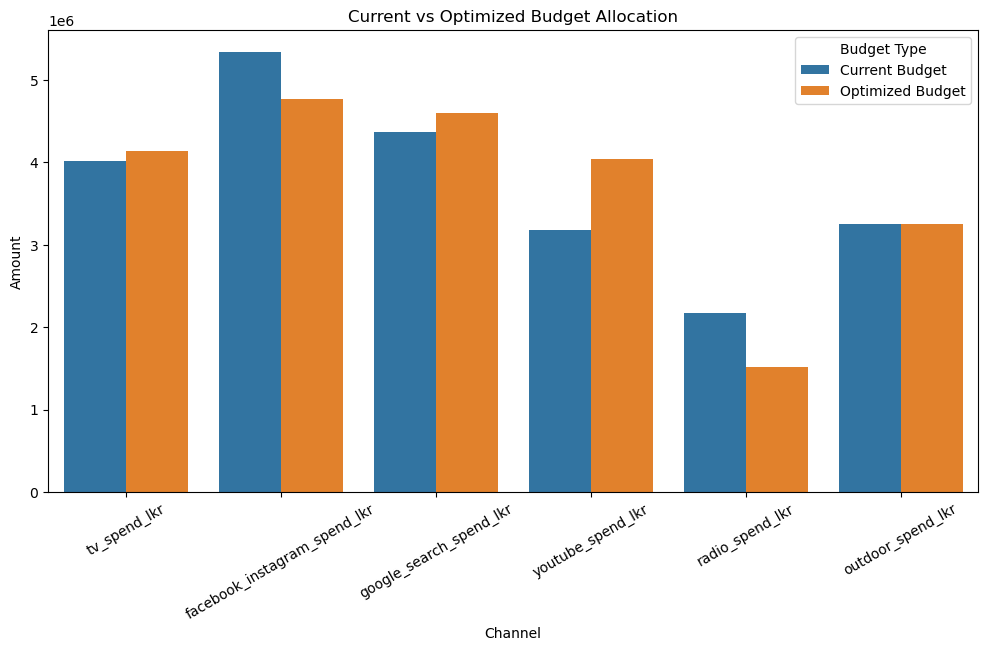

In [14]:
comparison_df = optimized_df.melt(
    id_vars="Channel",
    value_vars=[
        "Current Budget",
        "Optimized Budget"
    ],
    var_name="Budget Type",
    value_name="Amount"
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=comparison_df,
    x="Channel",
    y="Amount",
    hue="Budget Type"
)

plt.title(
    "Current vs Optimized Budget Allocation"
)

plt.xticks(rotation=30)

plt.show()

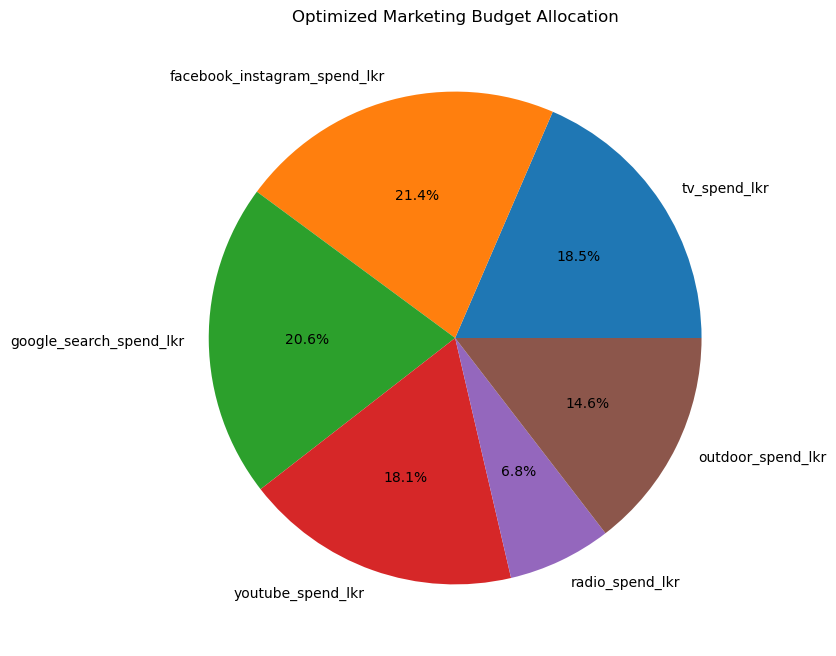

In [15]:
plt.figure(figsize=(8,8))

plt.pie(
    optimized_df["Optimized Budget"],
    labels=optimized_df["Channel"],
    autopct="%1.1f%%"
)

plt.title(
    "Optimized Marketing Budget Allocation"
)

plt.show()

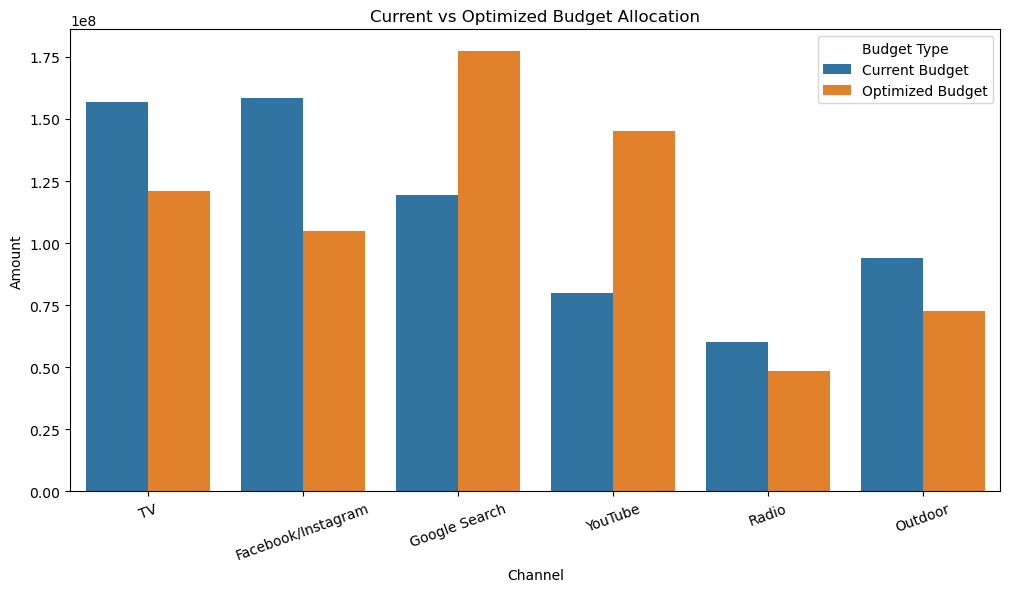

In [25]:
comparison_df = optimal_df.melt(
    id_vars="Channel",
    value_vars=[
        "Current Budget",
        "Optimized Budget"
    ],
    var_name="Budget Type",
    value_name="Amount"
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=comparison_df,
    x="Channel",
    y="Amount",
    hue="Budget Type"
)

plt.title("Current vs Optimized Budget Allocation")

plt.xticks(rotation=20)

plt.show()

Recommendations
Increase budget allocation for YouTube advertising because it generated the highest ROI (4.85).
Increase investment in Google Search advertising due to its strong sales contribution and high ROI (4.38).

Maintain investment in TV advertising while improving campaign efficiency.

Review Facebook and Instagram campaigns to improve return on investment.

Reduce budget allocation for Radio advertising since the MMM model indicates a negative ROI contribution.

Use MMM-based optimization results to guide future advertising budget planning.

Conclusion
The budget optimization model was developed using predictions generated by the Marketing Mix Model and optimized using the SciPy SLSQP algorithm under a fixed budget constraint.

The optimized allocation recommends increasing investment in Google Search and YouTube advertising channels while reducing expenditure on lower-performing channels such as Radio. The results demonstrate how data-driven optimization can improve marketing resource allocation and maximize expected business outcomes.